In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/processed/cars_preprocessed.csv")


df.shape

(752944, 32)

In [2]:
df.head()

,manufacturer,model,year,mileage,engine,transmission,drivetrain,fuel_type,mpg,exterior_color,...,is_one_owner,is_personal_use,engine_liters,mpg_high,mpg_low,mpg_avg,is_electric,transmission_type,transmission_gears,is_automatic
0,Acura,ILX Hybrid 1.5L,2013,92945.0,"1.5L I-4 i-VTEC variable valve control, engine...",Automatic,Front-wheel Drive,Gasoline,39-38,Black,...,0.0,0.0,1.5,39.0,38.0,38.5,0,Automatic,NaN,1
1,Acura,ILX Hybrid 1.5L,2013,47645.0,1.5L I4 8V MPFI SOHC Hybrid,Automatic CVT,Front-wheel Drive,Hybrid,39-38,Gray,...,1.0,1.0,1.5,39.0,38.0,38.5,0,CVT,NaN,1
2,Acura,ILX Hybrid 1.5L,2013,53422.0,1.5L I4 8V MPFI SOHC Hybrid,Automatic CVT,Front-wheel Drive,Hybrid,39-38,Bellanova White Pearl,...,1.0,1.0,1.5,39.0,38.0,38.5,0,CVT,NaN,1
3,Acura,ILX Hybrid 1.5L,2013,117598.0,1.5L I4 8V MPFI SOHC Hybrid,Automatic CVT,Front-wheel Drive,Hybrid,39-38,Polished Metal Metallic,...,1.0,1.0,1.5,39.0,38.0,38.5,0,CVT,NaN,1
4,Acura,ILX Hybrid 1.5L,2013,114865.0,1.5L I4 8V MPFI SOHC Hybrid,Automatic CVT,Front-wheel Drive,Hybrid,39-38,NaN,...,0.0,1.0,1.5,39.0,38.0,38.5,0,CVT,NaN,1


In [3]:
df["price"].describe()

count    7.529440e+05
mean     3.255284e+04
std      2.671448e+04
min      1.000000e+00
25%      1.959500e+04
50%      2.799000e+04
75%      3.948800e+04
max      8.888889e+06
Name: price, dtype: float64

In [4]:
df["price"].median()

np.float64(27990.0)

In [5]:
df["price"].quantile([0.25, 0.5, 0.75, 0.9, 0.95, 0.99])

0.25     19595.00
0.50     27990.00
0.75     39488.00
0.90     54560.40
0.95     68779.55
0.99    109994.00
Name: price, dtype: float64

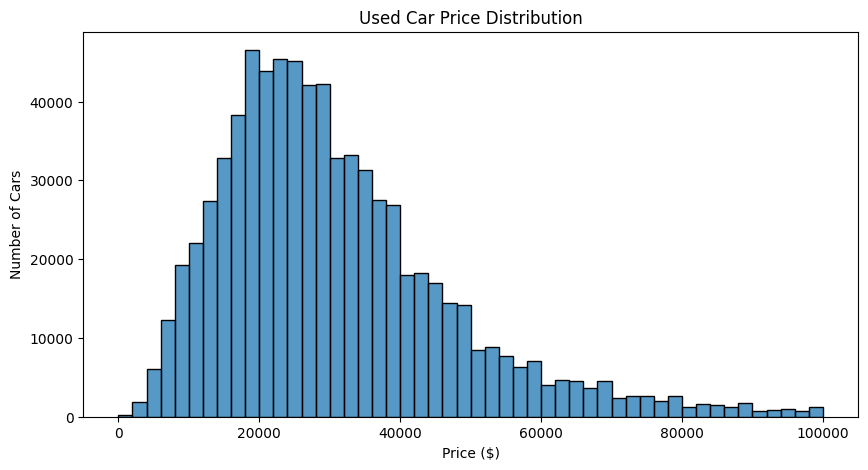

In [6]:
plt.figure(figsize=(10, 5))

sns.histplot(df[df["price"] <= 100000]["price"], bins=50)

plt.title("Used Car Price Distribution")
plt.xlabel("Price ($)")
plt.ylabel("Number of Cars")
plt.show()

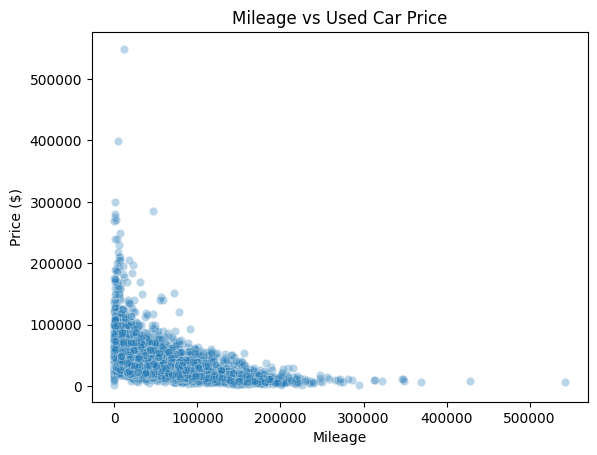

In [7]:
sample = df[["mileage", "price"]].dropna().sample(10000, random_state=42)

sns.scatterplot(data=sample, x="mileage", y="price", alpha=0.3)

plt.title("Mileage vs Used Car Price")
plt.xlabel("Mileage")
plt.ylabel("Price ($)")
plt.show()

In [8]:
df[["mileage", "price"]].corr()

,mileage,price
mileage,1.000000,-0.431566
price,-0.431566,1.000000


In [9]:
df[["vehicle_age", "price"]].corr()

,vehicle_age,price
vehicle_age,1.000000,-0.239945
price,-0.239945,1.000000


In [10]:
age_price = df.groupby("vehicle_age")["price"].median()

age_price.head(10)

vehicle_age
0    58420.0
1    49989.0
2    43970.0
3    36950.0
4    31478.0
5    29347.0
6    25989.0
7    22822.5
8    19998.0
9    17995.0
Name: price, dtype: float64

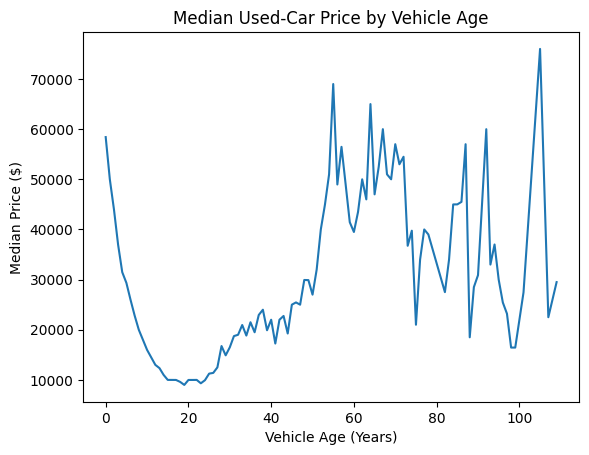

In [11]:

age_price.plot()

plt.title("Median Used-Car Price by Vehicle Age")
plt.xlabel("Vehicle Age (Years)")
plt.ylabel("Median Price ($)")
plt.show()

In [12]:
df.groupby("vehicle_age").size().tail(20)

vehicle_age
83     15
84     13
85      6
86      4
87      8
88      2
89      1
90      1
92     17
93     16
94     15
95     17
96     10
97      2
98      6
99      2
101     4
105     1
107     1
109     2
dtype: int64

In [13]:
manufacturer_price = (
    df.groupby("manufacturer")["price"]
      .median()
      .sort_values(ascending=False)
)

manufacturer_price

manufacturer
Porsche          68106.5
Tesla            44992.0
Land Rover       44990.0
RAM              41486.0
Mercedes-Benz    39795.0
Volvo            36588.5
GMC              35592.5
Lexus            34500.0
Cadillac         33995.0
Audi             33963.0
BMW              33452.0
Jaguar           31998.0
Lincoln          31819.5
INFINITI         30000.0
Ford             29459.0
Toyota           28990.0
Acura            28795.0
Jeep             27848.0
Chevrolet        26950.0
Subaru           25597.0
Honda            24998.0
Mazda            23995.0
Dodge            23249.0
Volkswagen       22994.0
Buick            22900.0
Chrysler         22590.0
Nissan           22400.0
Kia              20998.0
Hyundai          20395.0
Mitsubishi       19118.0
Name: price, dtype: float64

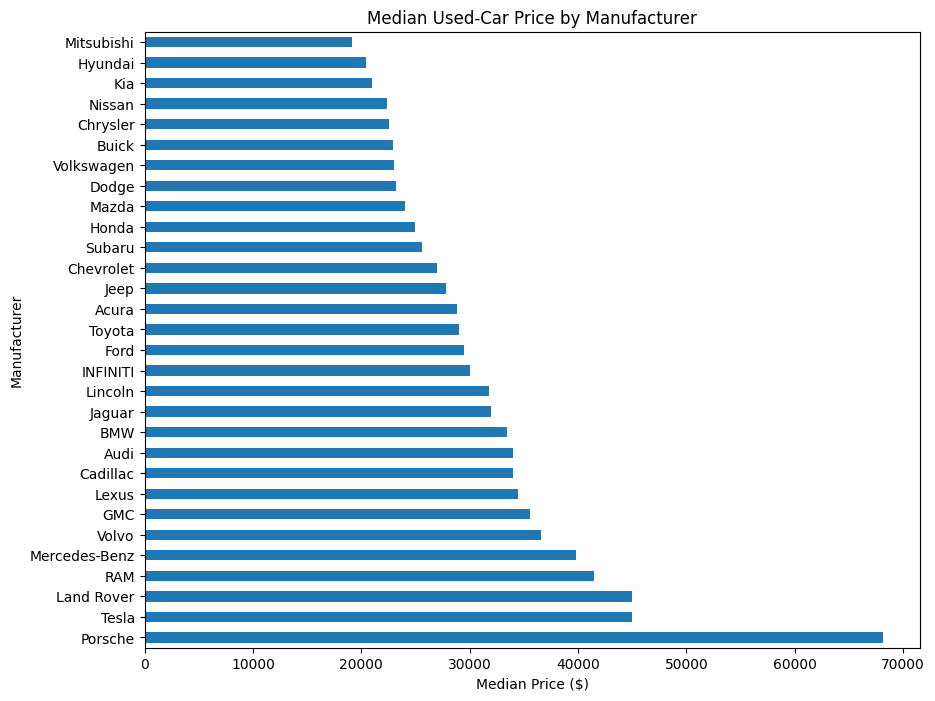

In [14]:
plt.figure(figsize=(10, 8))

manufacturer_price.plot(kind="barh")

plt.title("Median Used-Car Price by Manufacturer")
plt.xlabel("Median Price ($)")
plt.ylabel("Manufacturer")
plt.show()

In [15]:
df.groupby("has_accident")["price"].median()

has_accident
0.0    29991.0
1.0    21900.0
Name: price, dtype: float64

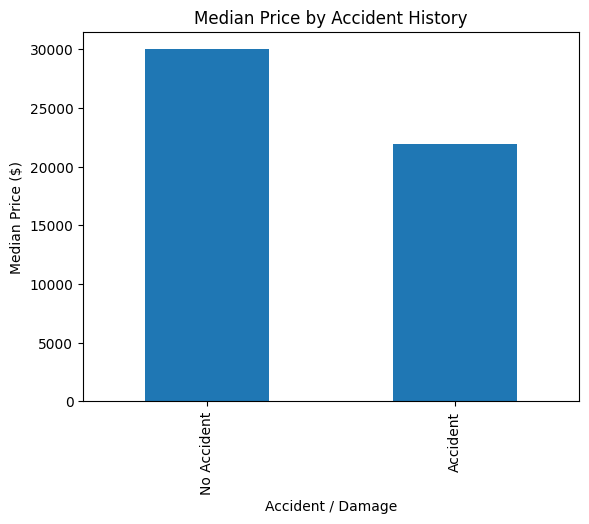

In [16]:
accident_price = df.groupby("has_accident")["price"].median()

accident_price.plot(kind="bar")

plt.title("Median Price by Accident History")
plt.xlabel("Accident / Damage")
plt.ylabel("Median Price ($)")
plt.xticks([0, 1], ["No Accident", "Accident"])
plt.show()

In [17]:
df.groupby("is_one_owner")["price"].median()

is_one_owner
0.0    21998.0
1.0    31989.0
Name: price, dtype: float64

In [18]:
df.groupby("fuel_type")["price"].median().sort_values(ascending=False)

fuel_type
Electric Fuel System             122470.0
PHEV                              53990.0
Diesel                            53950.0
Unspecified                       51999.0
Gasoline/Mild Electric Hybrid     50982.0
Biodiesel                         48995.0
Hybrid Fuel                       48672.0
Plug-In Electric/Gas              44250.0
Gas                               42885.5
Electric                          40812.0
Premium Unleaded                  39992.5
Regular Unleaded                  37745.0
Flex Fuel Capability              37375.0
Plug-In Hybrid                    36999.5
B                                 36999.0
G                                 35597.0
Gasoline Fuel                     31999.0
Hybrid                            31252.0
Gas/Electric Hybrid               27844.5
Gasoline                          26999.0
Natural Gas                       22500.0
Compressed Natural Gas            18997.0
Bio Diesel                        17977.0
Hydrogen Fuel Cell      

In [19]:
df["fuel_type"].value_counts().head(15)

fuel_type
Gasoline                         637166
Hybrid                            28926
Diesel                            27681
E85 Flex Fuel                     18518
Electric                          16117
B                                  1410
Flexible Fuel                       468
Plug-In Hybrid                      118
Gasoline Fuel                        77
Gasoline/Mild Electric Hybrid        70
Regular Unleaded                     54
Premium Unleaded                     48
G                                    44
Compressed Natural Gas               29
Unspecified                          25
Name: count, dtype: int64

In [20]:
df.groupby("manufacturer").agg(
    median_price=("price", "median"),
    median_mileage=("mileage", "median"),
    cars=("price", "count")
).sort_values("median_price", ascending=False).head(10)

,median_price,median_mileage,cars
manufacturer,,,
Porsche,68106.5,25289.5,11310
Tesla,44992.0,32120.0,5823
Land Rover,44990.0,42176.0,12153
RAM,41486.0,50339.0,19278
Mercedes-Benz,39795.0,35489.0,40461
Volvo,36588.5,32814.5,9948
GMC,35592.5,51784.0,29176
Lexus,34500.0,43903.5,20906
Cadillac,33995.0,42791.5,17472


In [21]:
df.groupby(["has_accident", "is_one_owner"])["price"].median()

has_accident  is_one_owner
0.0           0.0             23999.0
              1.0             32998.0
1.0           0.0             18700.0
              1.0             26500.0
Name: price, dtype: float64

In [22]:
price_variation = (
    df.groupby(["manufacturer", "model", "year"])["price"]
      .agg(["count", "median", "std"])
      .query("count >= 10")
)

price_variation.head()

count   median          std
manufacturer model year                             
Acura        ILX   2017     23  19995.0  2132.536890
                   2018     18  20994.0  2632.612962
                   2019     19  22995.0  2709.547942
                   2020     21  25999.0  2309.719366
                   2021     10  26934.5  3175.708427

In [23]:
price_variation["cv"] = (
    price_variation["std"] / price_variation["median"]
)

price_variation.sort_values("cv", ascending=False).head(10)

count   median  \
manufacturer  model                           year                   
Ford          Utility Police Interceptor Base 2016     53  13991.0   
RAM           ProMaster 3500 High Roof        2017     10  36051.5   
Nissan        Maxima 3.5 Platinum             2016     86  19826.0   
Porsche       911 Carrera                     2002     11  46999.0   
Land Rover    Defender 90 First Edition       2021     12  65612.5   
Jeep          Compass High Altitude           2017     39  17511.0   
Ford          Ranger                          2020     29  34997.0   
              Excursion Eddie Bauer           2003     11  16489.0   
              Mustang Base                    1967     11  55000.0   
Mercedes-Benz Metris Base                     2021     31  52335.0   

                                                             std         cv  
manufacturer  model                           year                           
Ford          Utility Police Interceptor Base 2016  1.219026e+06  87.129276  
RAM           ProMaster 3500 High Roof        2017  1.091983e+06  30.289539  
Nissan        Maxima 3.5 Platinum             2016  5.186081e+04   2.615798  
Porsche       911 Carrera                     2002  8.175766e+04   1.739562  
Land Rover    Defender 90 First Edition       2021  1.106073e+05   1.685765  
Jeep          Compass High Altitude           2017  2.927016e+04   1.671530  
Ford          Ranger                          2020  5.768895e+04   1.648397  
              Excursion Eddie Bauer           2003  2.579941e+04   1.564643  
              Mustang Base                    1967  8.334814e+04   1.515421  
Mercedes-Benz Metris Base                     2021  7.469853e+04   1.427315

In [24]:
df[df["price"] > 500000][
    ["manufacturer", "model", "year", "price"]
].sort_values("price", ascending=False).head(20)

,manufacturer,model,year,price
221401,Ford,Utility Police Interceptor Base,2016,8888889.0
83046,Cadillac,DeVille 77 HOURS ON ENGINES,1963,4999999.0
629064,RAM,ProMaster 3500 High Roof,2017,3490000.0
605344,Porsche,Carrera GT,2005,2250000.0
601312,Porsche,918 Spyder Base (PDK),2015,2099995.0
605339,Porsche,Carrera GT,2004,1899999.0
48588,BMW,750 iL,1996,1750000.0
605343,Porsche,Carrera GT,2005,1650000.0
210545,Ford,GT EDITION VIN 002,2018,1575000.0
605338,Porsche,Carrera GT Base (M6),2004,1549991.0


In [25]:
model_df = df[df["price"] <= 500000].copy()

model_df.shape


(752891, 32)

In [26]:
model_df["price"].describe()

count    752891.000000
mean      32466.180460
std       22034.348329
min           1.000000
25%       19595.000000
50%       27990.000000
75%       39485.000000
max      500000.000000
Name: price, dtype: float64